## Classifying Breast Tumors 

In this project, we will develop a model that predicts whether a breast tumor is benign or malignant using the Diagnostic Wisconsin Breast Cancer Dataset from the UCI Machine Learning Repository.

The dataset contains 569 tumor samples and 30 numerical features describing the charactersitics of a cell nuclei. We will be using a logistic regression model to classify the samples and determine the most meaningful features with respect to classifying the tumors.

### Importing Libraries and Exploratory Data Analysis

In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, roc_auc_score

In [2]:
df = pd.read_csv("breast+cancer+wisconsin+diagnostic/wdbc.data", header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       569 non-null    int64  
 1   1       569 non-null    object 
 2   2       569 non-null    float64
 3   3       569 non-null    float64
 4   4       569 non-null    float64
 5   5       569 non-null    float64
 6   6       569 non-null    float64
 7   7       569 non-null    float64
 8   8       569 non-null    float64
 9   9       569 non-null    float64
 10  10      569 non-null    float64
 11  11      569 non-null    float64
 12  12      569 non-null    float64
 13  13      569 non-null    float64
 14  14      569 non-null    float64
 15  15      569 non-null    float64
 16  16      569 non-null    float64
 17  17      569 non-null    float64
 18  18      569 non-null    float64
 19  19      569 non-null    float64
 20  20      569 non-null    float64
 21  21      569 non-null    float64
 22  22

In [4]:
feature_headers = [
    'ID', 'Diagnosis',
    'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
    'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1',
    'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2',
    'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2',
    'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3',
    'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3'
]

# Assigning the column names to the DataFrame
df.columns = feature_headers
df.head()

,ID,Diagnosis,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
df["Diagnosis"].value_counts()

Diagnosis
B    357
M    212
Name: count, dtype: int64

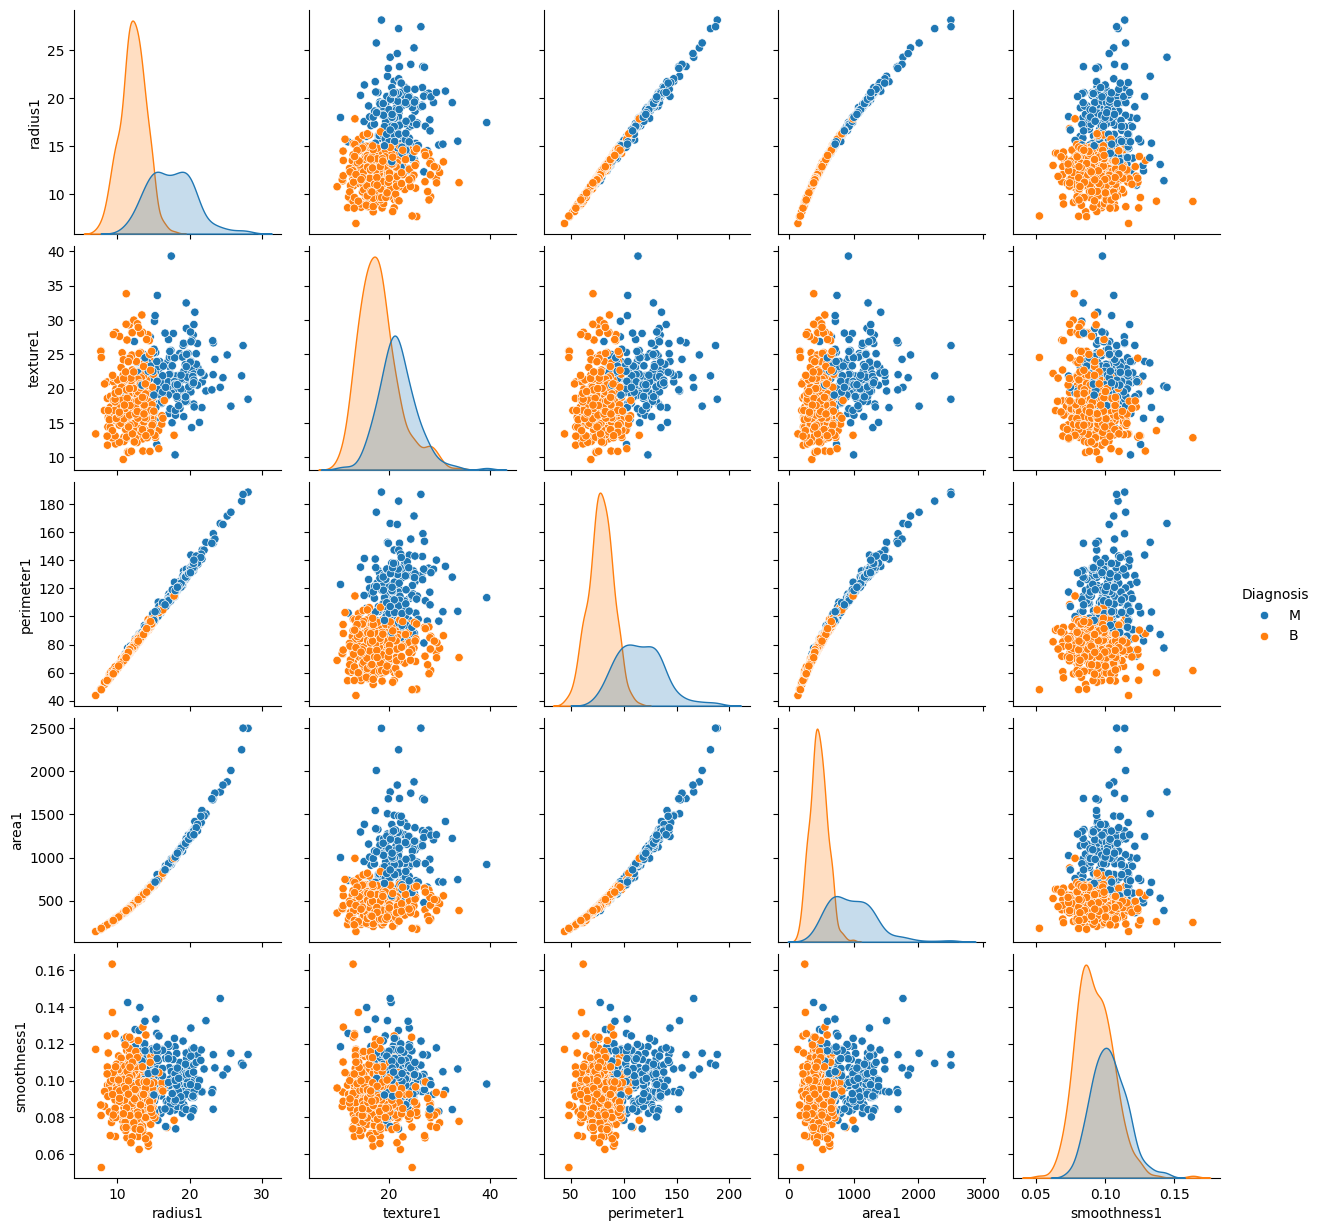

In [6]:
# Visualize the pairplot of the first 5 features colored by Diagnosis
sns.pairplot(df, hue="Diagnosis", vars=[
    'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1'
])
plt.show()

### Exploratory Pairplot (radius1, texture1, perimeter1, area1, smoothness1)
- radius1, perimeter1, and area1 are almost perfectly collinear (near-diagonal scatter plots), as expected geometrically — larger radius directly implies larger perimeter and area. This multicollinearity does not harm logistic regression given the StandardScaler pipeline, but it does mean these three features carry overlapping information.
- Malignant tumors (M) cluster at higher values of radius1, perimeter1, and area1, confirming that **larger tumor size strongly predicts malignancy**.
- texture1 shows moderate class separation with M tumors trending toward higher, more varied texture values.
- smoothness1 shows the least visual separation between M and B, making it the weakest discriminator of this first-feature group.


In [7]:
df["Diagnosis"] = df["Diagnosis"].map({"M": 1, "B": 0})
features = df.drop(["ID", "Diagnosis"], axis=1)
labels = df["Diagnosis"]

In [8]:
print("Shape of features:", features.shape)
print("Shape of labels:", labels.shape)
print("columns of features:", features.columns)

Shape of features: (569, 30)
Shape of labels: (569,)
columns of features: Index(['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
       'compactness1', 'concavity1', 'concave_points1', 'symmetry1',
       'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2',
       'smoothness2', 'compactness2', 'concavity2', 'concave_points2',
       'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3',
       'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3',
       'symmetry3', 'fractal_dimension3'],
      dtype='object')


### Train/Test Split

In [9]:
X = features.values
y = labels.values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print("Shape of X_train (training data):", X_train.shape)
print("Shape of y_train (training labels):", y_train.shape)
print("Shape of X_test (test data):", X_test.shape)
print("Shape of y_test (test labels):", y_test.shape)

Shape of X_train (training data): (398, 30)
Shape of y_train (training labels): (398,)
Shape of X_test (test data): (171, 30)
Shape of y_test (test labels): (171,)


### Pipeline Development

In [10]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=42))
])

pipeline.fit(X_train, y_train)
train_accuracy = pipeline.score(X_train, y_train)
test_accuracy = pipeline.score(X_test, y_test)

print("Training Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Training Accuracy: 0.9874371859296482
Test Accuracy: 0.9707602339181286


### Determining the Most Important Features
The most important features for classification can be determined by looking at the coefficients of the logistic regression model. We can extract the coefficients and identify which features have the highest absolute values, as these contribute most to the decision boundary of the model.


In [11]:
model_coefficients = pipeline.named_steps["classifier"].coef_[0]

feature_importance_df = pd.DataFrame({
    "Feature": features.columns,
    "Coefficient": model_coefficients,
    "Absolute Coefficient": np.abs(model_coefficients)
}).sort_values(by="Absolute Coefficient", ascending=False)

print(feature_importance_df.head(10))

            Feature  Coefficient  Absolute Coefficient
21         texture3     1.384327              1.384327
10          radius2     1.205130              1.205130
28        symmetry3     1.085744              1.085744
13            area2     0.912114              0.912114
15     compactness2    -0.904630              0.904630
23            area3     0.876082              0.876082
7   concave_points1     0.853924              0.853924
20          radius3     0.845014              0.845014
26       concavity3     0.832548              0.832548
6        concavity1     0.805938              0.805938


Note:
* positive coefficient = malignant
* negative coefficient = benign

The suffixes 1, 2, 3 attached to the Features correspond to the mean, standard error, and worst-case (largest) measurements respectively. 

The dominance of 3-suffix features (texture3, symmetry3, area3, concavity3) suggests that **worst-case measurements are especially informative**. Extreme cell behavior is a stronger malignancy signal than average behavior. 

Most high-importance features positively predict malignancy. The single notable negative coefficient, compactness2, suggests that higher variability in compactness is actually associated with benign tumors.

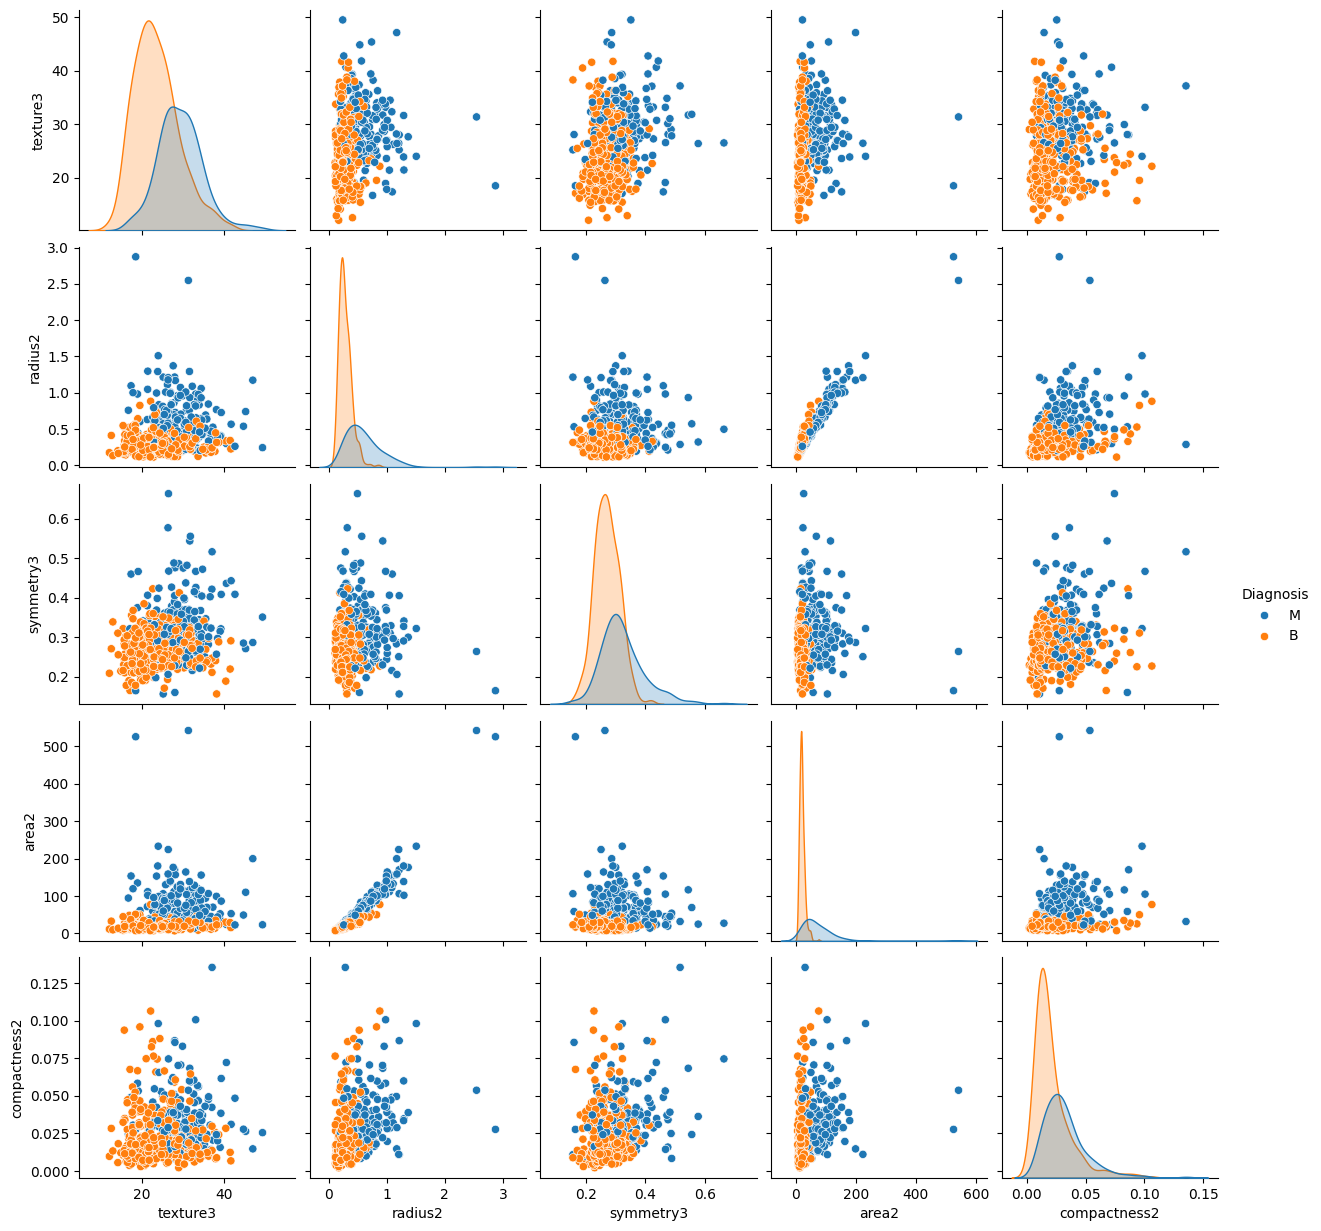

In [ ]:
#Visualize the pairplot of the top 5 most important features colored by Diagnosis
# Malignant was originally blue and Benign was originally orange, so we will keep that color scheme by mapping 1 back to "M" and 0 back to "B"
df["Diagnosis"] = df["Diagnosis"].map({1: "M", 0: "B"})
top_features = feature_importance_df.head(5)["Feature"].values
sns.pairplot(df, hue="Diagnosis", vars=top_features)
plt.show()

### Model Evaluation

For both the training and test datasets:
1. Generate a confusion matrix
2. Calculate the  F1-score, Precision, Recall, and False alarm rate.
3. Plot the ROC curve and report the AUC.

### Training Data Metrics

Training Confusion Matrix:
 [[250   0]
 [  5 143]]
Training Precision: 1.0
Training Recall: 0.9662162162162162
Training F1 Score: 0.9828178694158075
Training False Alarm Rate: 0.0
Training AUC: 0.9972432432432432


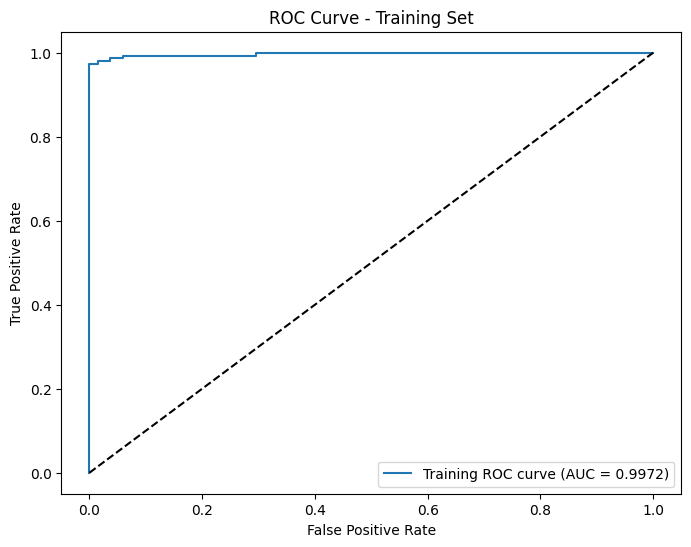

In [18]:
train_confusion_matrix = confusion_matrix(y_train, pipeline.predict(X_train))
train_precision = precision_score(y_train, pipeline.predict(X_train))
train_recall = recall_score(y_train, pipeline.predict(X_train))
train_f1 = f1_score(y_train, pipeline.predict(X_train))

# To get the false alarm rate, we need to calculate the number of false positives (FP) and true negatives (TN) from the confusion matrix. 
# The false alarm rate is calculated as FP / (FP + TN).
train_false_alarm_rate = train_confusion_matrix[0][1] / (train_confusion_matrix[0][0] + train_confusion_matrix[0][1])

train_auc = roc_auc_score(y_train, pipeline.predict_proba(X_train)[:, 1])

print("Training Confusion Matrix:\n", train_confusion_matrix)
print("Training Precision:", train_precision)
print("Training Recall:", train_recall)
print("Training F1 Score:", train_f1)
print("Training False Alarm Rate:", train_false_alarm_rate)
print("Training AUC:", train_auc)

# ROC Curve and AUC for the training set using matplotlib
fpr_train, tpr_train, thresholds_train = roc_curve(y_train, pipeline.predict_proba(X_train)[:, 1])
plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, label=f'Training ROC curve (AUC = {train_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line for random guessing
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Training Set')
plt.legend(loc='lower right')
plt.show()

### Training Set
- Confusion matrix: TN=250, FP=0, FN=5, TP=143
- Precision: **1.000** - zero false positives on the training set
- Recall: **96.62%** - 5 malignant tumors were missed
- F1 Score: **0.9828**
- False Alarm Rate: **0.0%**
- AUC: **0.9972**

### Test Data Metrics

Testing Confusion Matrix:
 [[106   1]
 [  4  60]]
Testing Precision: 0.9836065573770492
Testing Recall: 0.9375
Testing F1 Score: 0.96
Testing False Alarm Rate: 0.009345794392523364
Testing AUC: 0.997517523364486


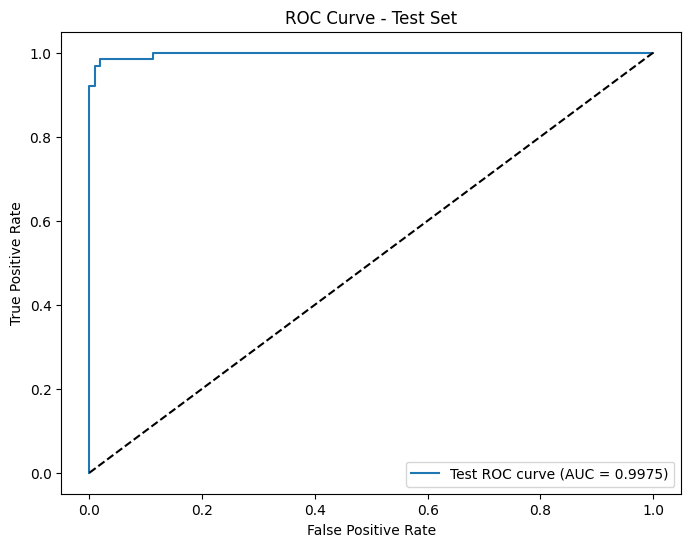

In [19]:
test_confusion_matrix = confusion_matrix(y_test, pipeline.predict(X_test))
test_precision = precision_score(y_test, pipeline.predict(X_test))
test_recall = recall_score(y_test, pipeline.predict(X_test))
test_f1 = f1_score(y_test, pipeline.predict(X_test))

# To get the false alarm rate, we need to calculate the number of false positives (FP) and true negatives (TN) from the confusion matrix. 
# The false alarm rate is calculated as FP / (FP + TN).
test_false_alarm_rate = test_confusion_matrix[0][1] / (test_confusion_matrix[0][0] + test_confusion_matrix[0][1])

test_auc = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1])

print("Testing Confusion Matrix:\n", test_confusion_matrix)
print("Testing Precision:", test_precision)
print("Testing Recall:", test_recall)
print("Testing F1 Score:", test_f1)
print("Testing False Alarm Rate:", test_false_alarm_rate)
print("Testing AUC:", test_auc)

# ROC Curve and AUC for the test set using matplotlib
fpr_test, tpr_test, thresholds_test = roc_curve(y_test, pipeline.predict_proba(X_test)[:, 1])
plt.figure(figsize=(8, 6))
plt.plot(fpr_test, tpr_test, label=f'Test ROC curve (AUC = {test_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line for random guessing
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend(loc='lower right')
plt.show()

### Test Set
- Confusion matrix: TN=106, FP=1, FN=4, TP=60
- Precision: **98.36%** — only 1 benign tumor was misclassified as malignant
- Recall: **93.75%** — 4 malignant tumors were missed
- F1 Score: **0.9600**
- False Alarm Rate: **0.93%**
- AUC: **0.9975**

The test AUC of **0.9975** is near-perfect and is actually marginally higher than the training AUC (0.9972), indicating that the model's probabilistic ranking of malignancy is extremely reliable and shows no sign of overfitting in terms of discriminative ability. The 4 false negatives (missed malignant tumors) on the test set are the most clinically critical errors — in a medical screening context, minimizing these at the cost of slightly more false alarms would be desirable, which could be achieved by lowering the classification threshold.

### Overall Conclusion

| Split | Accuracy |
|-------|----------|
| Training | **98.74%** |
| Test | **97.08%** |

The model generalizes well with only a ~1.66 percentage point drop from training to test accuracy. This small gap indicates that the model is not significantly overfitting, and that logistic regression paired with standard scaling is a strong fit for this dataset.

The logistic regression model trained on the Wisconsin Breast Cancer dataset achieves excellent performance, with a test accuracy of **97.08%**, an F1 score of **0.96**, and an AUC of **0.9975**. The model is well-calibrated and generalizes effectively. The most predictive features are dominated by worst-case measurements of texture, radius, symmetry, area, and concavity, underscoring that **the extremes of cellular morphology matter more than the average**. The near-zero false alarm rate and high precision make this model particularly suitable as a first-pass screening tool, though a threshold adjustment could further reduce the clinically costly false negatives.